In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[1] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# Clear the cache if needed
# adapter.clear_cache()

# Imbalance
df_imbalance = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="Imbalance"
)
df_imbalance = df_imbalance.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                         pl.col("symbol").cast(pl.Categorical))
df_imbalance = df_imbalance.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')


# OHLCV-1s
df_bars = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="OHLCV-1s"
)
df_bars = df_bars.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                               pl.col("symbol").cast(pl.Categorical))
df_bars = df_bars.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')


# Statistics (for auction price)
df_stats = await adapter.get_data(
    tickers="ALL_SYMBOLS",
    start_date="2026-04-26",
    end_date="2026-05-26",
    dataset="XNAS.ITCH",
    schema="statistics"
)
df_stats = df_stats.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                 pl.col("symbol").cast(pl.Categorical))
df_stats = df_stats.filter(pl.col('stat_type') == 11).sort('ts_event')

[GenericAdapter] Parquet cache hit: eed2c43bde309e55f1128616fc429a3d.parquet
[GenericAdapter] Parquet cache hit: 9a7375241335b23022acda39f4056932.parquet
[GenericAdapter] Parquet cache hit: e1ca758114d6707a5b8044dbede2d432.parquet


### Cleaning Data
Joining all together

In [2]:
temp = df_imbalance
print(f"Unique Symbols (Imbalance): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Imbalance): 12800


['ts_recv',
 'ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'ref_price',
 'auction_time',
 'cont_book_clr_price',
 'auct_interest_clr_price',
 'ssr_filling_price',
 'ind_match_price',
 'upper_collar',
 'lower_collar',
 'paired_qty',
 'total_imbalance_qty',
 'market_imbalance_qty',
 'unpaired_qty',
 'auction_type',
 'side',
 'auction_status',
 'freeze_status',
 'num_extensions',
 'unpaired_side',
 'significant_imbalance',
 'symbol']

In [3]:
temp = df_bars
print(f"Unique Symbols (Bars): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Bars): 12589


['ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'symbol']

In [4]:
temp = df_stats
print(f"Unique Symbols (Stats): {temp.select("symbol").n_unique()}")
temp.columns

Unique Symbols (Stats): 12800


['ts_recv',
 'ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'ts_ref',
 'price',
 'quantity',
 'sequence',
 'ts_in_delta',
 'stat_type',
 'channel_id',
 'update_action',
 'stat_flags',
 'symbol']

In [5]:
# daily volume before the final 10mins
session_dollar_volume = (df_bars.lazy()
                         .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
                         .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
                         .group_by(["date", "symbol"])
                         .agg(
                             (pl.col('volume') * pl.col("close")).sum() #approximated using seconds closing prices
                             )
                        ).rename({"volume": "session_dollar_volume", "symbol": "symbol"}).sort("date")

In [6]:
imbalance_cols = ["ts_event", "symbol", "ref_price", "side",
        "total_imbalance_qty", "paired_qty", 
        "cont_book_clr_price", "auct_interest_clr_price"]
df = (
      df_bars.lazy()
      .select(["ts_event", "close", "volume", "symbol"])
      .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50), pl.time(16,0)))
      .join(
          df_imbalance.lazy()
              .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50), pl.time(16,0)))
              .select(imbalance_cols)
              .with_columns(pl.col("ts_event").dt.truncate("1s"))
              .group_by(["symbol", "ts_event"])
              .agg(
                  pl.col("ref_price").last(),
                  pl.col("side").last(),
                  pl.col("total_imbalance_qty").last(),
                  pl.col("paired_qty").last(),
                  pl.col("cont_book_clr_price").last(),
                  pl.col("auct_interest_clr_price").last(),
              ),
          on=["ts_event", "symbol"], how="left",
      )
      .with_columns(pl.col("ts_event").dt.date().alias("_d"))
      .sort(["symbol", "_d", "ts_event"])
      .with_columns(
          pl.col(imbalance_cols)
            .forward_fill().over(["symbol","_d"])
      )
      .drop("_d")
      .sort("ts_event")
      .collect(engine="streaming")    # try this first; fall back to default if it errors
  )

In [7]:
# create data with a qty_signal, grouped by ts_event and symbol
data = (
    df.lazy()
    # day key (00:00:00 UTC) to match session_dollar_volume's ts_event
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .join(
        session_dollar_volume,
        on=["date", "symbol"],
        how="left",
    )
    .with_columns(
        (
            pl.when(pl.col("side") == "A").then(-1.0)
            .when(pl.col("side") == "B").then(1.0)
            .otherwise(0.0)
            * pl.col("total_imbalance_qty") * pl.col("close")
            / pl.col("session_dollar_volume")
        ).alias("qty_signal")
    )
    .drop("date")
    .sort("ts_event")
    # .fill_null(0)
    .select(imbalance_cols + ['qty_signal', 'session_dollar_volume', 'close', 'volume'])
    .collect(engine="streaming")
)

# Filter to the last 10 mins
# data = data.filter(pl.col("ts_event").dt.time().is_between(pl.time(15,00), pl.time(16,00)))

data

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64
2026-04-27 15:50:00 EDT,"""AAP""",0.0,"""N""",0,0,0.0,0.0,0.0,4.4578e6,57.69,124
2026-04-27 15:50:00 EDT,"""AAUC""",0.0,"""N""",0,0,0.0,0.0,0.0,5.7222e6,30.55,280
2026-04-27 15:50:00 EDT,"""ABEO""",5.32,"""A""",11057,14213,0.0,0.0,-0.121213,485743.095,5.325,1
2026-04-27 15:50:00 EDT,"""ACA""",0.0,"""N""",0,0,0.0,0.0,0.0,3.1604e6,120.27,101
2026-04-27 15:50:00 EDT,"""ADI""",392.66,"""B""",55984,439567,0.0,0.0,0.149101,1.4744e8,392.66,1596
…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22 16:00:00 EDT,"""YOUL""",null,null,null,null,null,null,null,1904.738,0.6302,300
2026-05-22 16:00:00 EDT,"""ZD""",43.71,"""A""",3275,170396,43.69,43.69,-0.034113,4.1954e6,43.7,172974
2026-05-22 16:00:00 EDT,"""ZEO""",0.8501,"""N""",0,1096,0.8501,0.8501,0.0,7841.013,0.8502,1096


In [8]:
# Overwrite the 20:00:00 bar's close/volume with the real close-auction execution from df_stats
# price/quantity from df_stats (stat_type 11 = closing price, one row per date).
df_close_auction = (
    df_stats
    .filter(pl.col('stat_type') == 11)
    .select(
        pl.col('ts_event').dt.date().alias('date'),
        pl.col('price').alias('auction_price'),
        pl.col('quantity').cast(pl.UInt64).alias('auction_qty'),
        pl.col('symbol').alias('symbol')
    )
)

data = (
    data
    .with_columns(pl.col('ts_event').dt.date().alias('date'))
    .join(df_close_auction, on=['date', 'symbol'], how='left')
    .with_columns(
        close=pl.when(pl.col('ts_event').dt.time() == pl.time(16, 00, 00))
                .then(pl.col('auction_price'))
                .otherwise(pl.col('close')),
        volume=pl.when(pl.col('ts_event').dt.time() == pl.time(16, 00, 00))
                .then(pl.col('auction_qty'))
                .otherwise(pl.col('volume')),
        near_pct_gap = ((pl.col("cont_book_clr_price") - pl.col("close")) / pl.col("close"))
    )
    .drop(['date', 'auction_price', 'auction_qty'])
    .sort('ts_event')
)
data

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume,near_pct_gap
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64,f64
2026-04-27 15:50:00 EDT,"""AAP""",0.0,"""N""",0,0,0.0,0.0,0.0,4.4578e6,57.69,124,-1.0
2026-04-27 15:50:00 EDT,"""AAUC""",0.0,"""N""",0,0,0.0,0.0,0.0,5.7222e6,30.55,280,-1.0
2026-04-27 15:50:00 EDT,"""ABEO""",5.32,"""A""",11057,14213,0.0,0.0,-0.121213,485743.095,5.325,1,-1.0
2026-04-27 15:50:00 EDT,"""ACA""",0.0,"""N""",0,0,0.0,0.0,0.0,3.1604e6,120.27,101,-1.0
2026-04-27 15:50:00 EDT,"""ADI""",392.66,"""B""",55984,439567,0.0,0.0,0.149101,1.4744e8,392.66,1596,-1.0
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-22 16:00:00 EDT,"""YOUL""",null,null,null,null,null,null,null,1904.738,0.6302,300,null
2026-05-22 16:00:00 EDT,"""ZD""",43.71,"""A""",3275,170396,43.69,43.69,-0.034113,4.1954e6,43.7,172723,-0.000229
2026-05-22 16:00:00 EDT,"""ZEO""",0.8501,"""N""",0,1096,0.8501,0.8501,0.0,7841.013,0.8502,1096,-0.000118


In [9]:
import gc
del df_imbalance
del df_bars
del df_stats
del df
gc.collect()

35

### Quick IC Studies

#### QTY_SIGNAL

In [10]:
# End-of-day close per (date, symbol)
close = (
    data
    .group_by_dynamic(index_column="ts_event", group_by="symbol", every="1d")
    .agg(pl.col("close").last().alias("close_eod"))
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select(["date", "symbol", "close_eod"])
)

# Decision-time snapshot per (date, symbol)
dt = pl.time(15, 55, 30)
snap = (
    data
    .filter(pl.col("ts_event").dt.truncate("1s").dt.time() == dt)
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .select(["date", "symbol", "side",
            pl.col("close").alias("close_dt"),
            "qty_signal", "near_pct_gap", "session_dollar_volume"])
)

# One row per (date, symbol) with both the signal and the realized return-to-close
panel = (
    snap.join(close, on=["date", "symbol"], how="inner")
    .with_columns(
        ((pl.col("close_eod") - pl.col("close_dt")) / pl.col("close_dt")).alias("ret")
    )
    .drop_nulls(["ret", "qty_signal", "near_pct_gap"])
    .with_columns(
      pl.col("session_dollar_volume").rank(method="min").over("date").alias("_rk"),
      pl.len().over("date").alias("_n"),
  )
  .filter(pl.col("_rk") / pl.col("_n") >= 0.90)   # keep top 90% by ADV each day
  .drop(["_rk", "_n"])
)

# Cross-sectional IC (Spearman across symbols, per day — usually what you want for an alpha):
daily_ic = (
      panel
      .filter(pl.col("side") != "N",
              pl.col('qty_signal').abs() > 0.01,
              pl.col('near_pct_gap').abs() != 1.0)
      .group_by("date")
      .agg(
          pl.corr(pl.col("qty_signal").rank(), pl.col("ret").rank()).alias("ic"),
          pl.corr(pl.col("near_pct_gap").rank(), pl.col("ret").rank()).alias("gap_ic"),
          pl.corr(pl.col("qty_signal"), pl.col("ret")).alias("pearson"),
          pl.corr(pl.col("qty_signal"), pl.col("near_pct_gap")).alias("colinearity"),
          pl.len().alias("n_symbols"),                            # sanity-check the universe
      )
      .sort("date")
  ) 
mean_ic = daily_ic["ic"].mean()
mean_corr = daily_ic["pearson"].mean()
mean_gap_ic = daily_ic["gap_ic"].mean()
mean_co = daily_ic["colinearity"].mean()

print(f"Mean IC: {mean_ic:,.2f}")
print(f"Mean Gap IC: {mean_gap_ic:,.2f}")
print(f"Mean Pearson Corr: {mean_corr:,.2f}")
print(f"Mean Signal Corr: {mean_co:,.2f}")

Mean IC: 0.19
Mean Gap IC: 0.22
Mean Pearson Corr: 0.13
Mean Signal Corr: 0.77


In [11]:
plot_panel = panel.filter(pl.col("side") != "N",
                          pl.col('qty_signal').abs() > 0.01,
                          pl.col('near_pct_gap').abs() != 1.0)

print(f"Num Samples: {len(plot_panel)}")

Num Samples: 902


In [47]:
# PnL if you bought 1 share of each row, going long on positive ret
# and short on negative ret (always capturing |close_eod - close_dt|).
pnl = (
    plot_panel
    .with_columns(
        (pl.col("close_dt") * pl.col("ret").abs()).alias("pnl_per_share"),
        pl.col("ret").abs().alias("abs_ret"),
    )
)

# (1) Per-trade view: weighted avg |ret|, weighted by notional
total_pnl = pnl["pnl_per_share"].sum()
total_notional_all = pnl["close_dt"].sum()
per_trade_ret = total_pnl / total_notional_all

# (2) Daily view: assume capital is recycled each day
daily = (
    pnl
    .group_by("date")
    .agg(
        pl.col("pnl_per_share").sum().alias("day_pnl"),
        pl.col("close_dt").sum().alias("day_notional"),
        pl.len().alias("n_trades"),
    )
    .with_columns((pl.col("day_pnl") / pl.col("day_notional")).alias("day_ret"))
    .sort("date")
)
mean_daily_ret = daily["day_ret"].mean()
n_days = len(daily)

# (3) Compounded monthly return (redeploy each day)
compounded = float((1.0 + daily["day_ret"]).product() - 1.0)

print(f"Trades: {len(plot_panel):,}  |  Trading days: {n_days}")
print(f"Total $ PnL: ${total_pnl:,.2f}")
print()
print("(1) Per-trade weighted avg |ret| (capital NOT recycled):")
print(f"    {per_trade_ret:.4%}  ({per_trade_ret*1e4:.1f} bps)")
print()
print("(2) Daily return (capital recycled each day):")
print(f"    Mean daily return: {mean_daily_ret:.4%}  ({mean_daily_ret*1e4:.1f} bps)")
print(f"    Annualized (x252): {(1 + mean_daily_ret)**252 - 1:.2%}")

daily

Trades: 902  |  Trading days: 20
Total $ PnL: $557.11

(1) Per-trade weighted avg |ret| (capital NOT recycled):
    0.1881%  (18.8 bps)

(2) Daily return (capital recycled each day):
    Mean daily return: 0.1863%  (18.6 bps)
    Annualized (x252): 59.86%


date,day_pnl,day_notional,n_trades,day_ret
"datetime[ns, America/New_York]",f64,f64,u32,f64
2026-04-27 00:00:00 EDT,16.305,12599.925,39,0.001294
2026-04-28 00:00:00 EDT,25.09,15541.57,49,0.001614
2026-04-29 00:00:00 EDT,19.19,10434.45,37,0.001839
2026-04-30 00:00:00 EDT,38.26,14648.3,45,0.002612
2026-05-01 00:00:00 EDT,23.615,14117.355,40,0.001673
…,…,…,…,…
2026-05-18 00:00:00 EDT,15.63,9725.67,35,0.001607
2026-05-19 00:00:00 EDT,29.21,15295.38,42,0.00191
2026-05-20 00:00:00 EDT,23.375,15158.615,45,0.001542


In [13]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
date = pl.date(2026,5,15)
X = (panel
     .filter(
         pl.col("side") != "N",
         pl.col('qty_signal').abs() > 0.01,
         pl.col('near_pct_gap').abs() != 1.0,
         pl.col("date").dt.date() == date
     )
     .select(["near_pct_gap"])
     .to_numpy()
)

y = (
    panel
     .filter(
         pl.col("side") != "N",
         pl.col('qty_signal').abs() > 0.01,
         pl.col('near_pct_gap').abs() != 1.0,
         pl.col("date").dt.date() == date
     )
     .select(["ret"])
     .to_numpy()
)

X_train, y_train = X[:int(len(X) * 0.8)], y[:int(len(X) * 0.8)]
X_test, y_test = X[int(len(X) * 0.8):], y[int(len(X) * 0.8):]


lr = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=0.010).fit(X_train, y_train)
print(f"OLS: Beta_near: {lr.coef_[0,0]:,.4f}, Beta_0: {lr.intercept_[0]:,.4f}")
print(f"OLS r_squared: {lr.score(X_train, y_train):,.3f}")

print(f"ridge: Beta_near: {ridge.coef_[0]:,.4f}, Beta_0: {ridge.intercept_[0]:,.4f}")
print(f"Ridge r_squared: {ridge.score(X_train, y_train):,.3f}")


OLS: Beta_near: 0.0437, Beta_0: 0.0011
OLS r_squared: 0.144
ridge: Beta_near: 0.0341, Beta_0: 0.0009
Ridge r_squared: 0.137


In [14]:
import statsmodels.api as sm
import numpy as np

# 1. Setup your data (X and y)
# Ensure X includes the intercept column if needed
X_train_sm = sm.add_constant(X_train)

# 2. Initialize the Ordinary Least Squares model
model = sm.OLS(endog=y_train, exog=X_train_sm)

# 3. Fit the model using Ridge Regularization (L1_wt=0)
# alpha controls the penalty strength
results = model.fit()

# 4. View your regularized coefficients
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.144
Model:                            OLS   Adj. R-squared:                  0.127
Method:                 Least Squares   F-statistic:                     8.584
Date:                Thu, 28 May 2026   Prob (F-statistic):            0.00506
Time:                        11:54:12   Log-Likelihood:                 237.27
No. Observations:                  53   AIC:                            -470.5
Df Residuals:                      51   BIC:                            -466.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0011      0.000      2.323      0.0

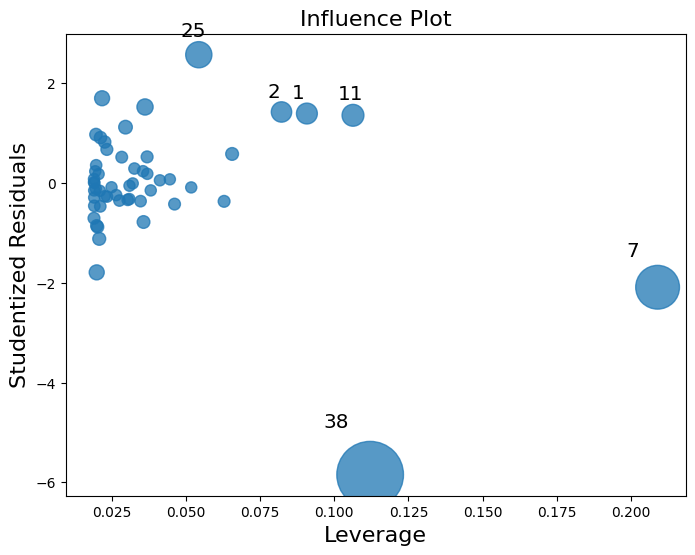

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.influence_plot(results, ax=ax)
plt.show()

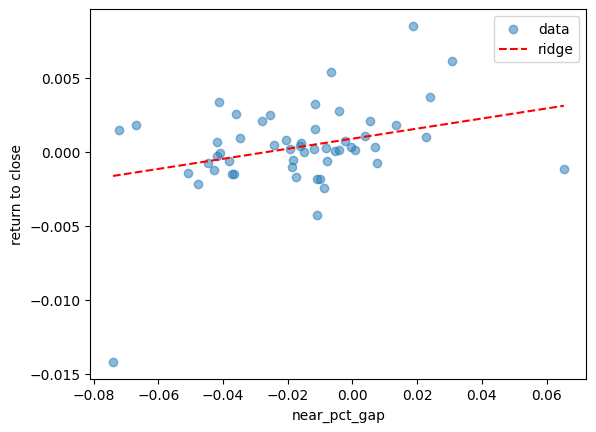

In [16]:
plt.scatter(X_train, y_train, color='tab:blue', alpha=0.5, label='data')
xline = np.linspace(np.min(X_train), np.max(X_train))
plt.plot(xline, xline * ridge.coef_[0] + ridge.intercept_[0], color='red', linestyle='--', linewidth=1.5, alpha=1, label='ridge')
plt.legend()
plt.xlabel("near_pct_gap")
plt.ylabel("return to close")
plt.show()
yhat = ridge.predict(X_test)

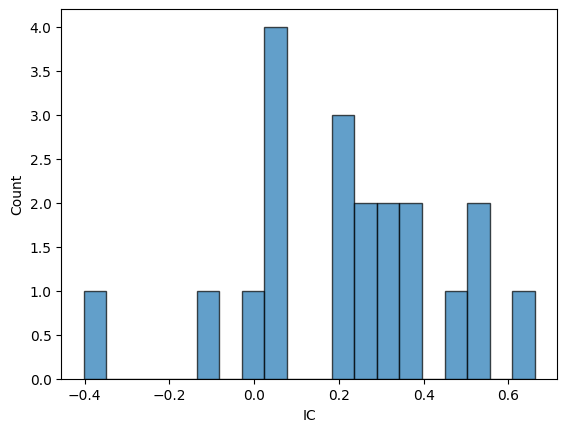

In [17]:
plt.hist(daily_ic["gap_ic"], edgecolor='black', alpha=0.7, bins=20)
plt.xlabel("IC")
plt.ylabel("Count")
plt.show()

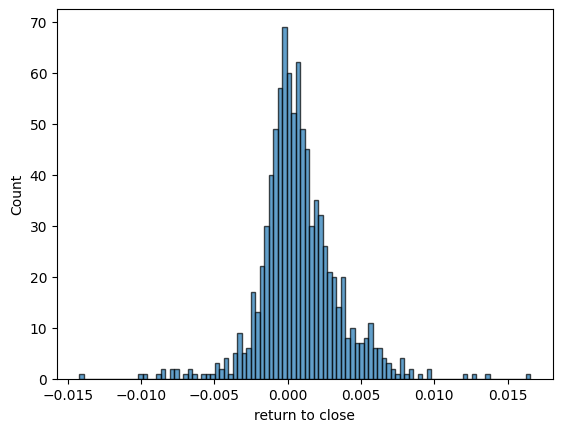

Jarque-Beta: stat=757.58, pval=0.00


In [18]:
plt.hist(plot_panel["ret"], edgecolor='black', alpha=0.7, bins=100)
plt.xlabel("return to close")
plt.ylabel("Count")
plt.show()

from scipy.stats import jarque_bera
stat, pval = jarque_bera(plot_panel['ret'])
print(f"Jarque-Beta: stat={stat:,.2f}, pval={pval:,.2f}")

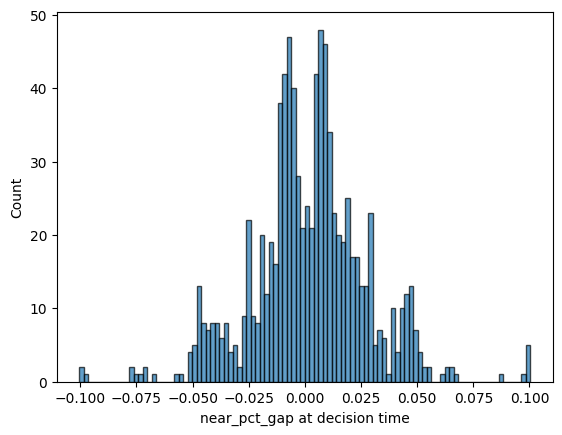

Jarque-Beta: stat=111.42, pval=0.00


In [19]:
plt.hist(plot_panel["near_pct_gap"], edgecolor='black', alpha=0.7, bins=100)
plt.xlabel("near_pct_gap at decision time")
plt.ylabel("Count")
plt.show()

from scipy.stats import jarque_bera
stat, pval = jarque_bera(plot_panel['near_pct_gap'])
print(f"Jarque-Beta: stat={stat:,.2f}, pval={pval:,.2f}")

#### Near Price + Paired QTY

In [20]:
plot_df = data.filter(
    pl.col('ts_event').dt.time().is_between(pl.time(15,55,00), pl.time(16,00,00)),
    pl.col('ts_event').dt.date() == pl.date(2026, 5, 22),
    pl.col('symbol') == "AMZN"
)
plot_df.head()

ts_event,symbol,ref_price,side,total_imbalance_qty,paired_qty,cont_book_clr_price,auct_interest_clr_price,qty_signal,session_dollar_volume,close,volume,near_pct_gap
"datetime[ns, America/New_York]",cat,f64,str,u32,u32,f64,f64,f64,f64,f64,u64,f64
2026-05-22 15:55:00 EDT,"""AMZN""",266.82,"""A""",348595,3298361,263.74,263.07,-0.083791,1.1098e9,266.76,6110,-0.011321
2026-05-22 15:55:01 EDT,"""AMZN""",266.76,"""A""",307351,3339605,264.18,263.58,-0.073891,1.1098e9,266.81,1471,-0.009857
2026-05-22 15:55:02 EDT,"""AMZN""",266.81,"""A""",308714,3338242,264.24,263.58,-0.074219,1.1098e9,266.81,1236,-0.009632
2026-05-22 15:55:03 EDT,"""AMZN""",266.81,"""A""",308714,3338242,264.23,263.58,-0.074227,1.1098e9,266.84,20,-0.009781
2026-05-22 15:55:04 EDT,"""AMZN""",266.83,"""A""",336620,3310336,264.24,263.58,-0.08094,1.1098e9,266.85,1441,-0.009781


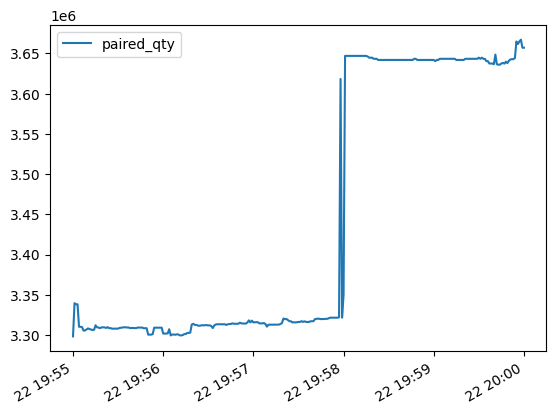

In [21]:
plt.plot(plot_df['ts_event'], plot_df['paired_qty'], label='paired_qty', color='tab:blue')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

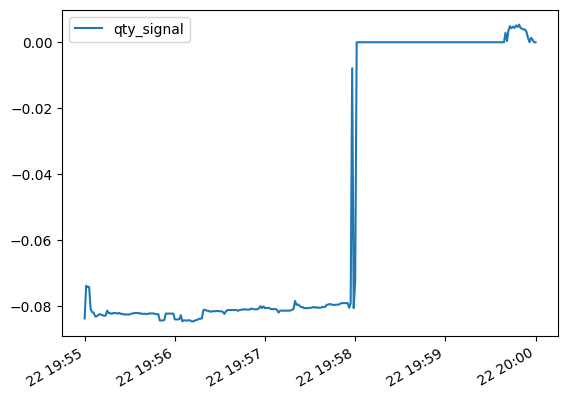

In [22]:
plt.plot(plot_df['ts_event'], plot_df['qty_signal'], label='qty_signal', color='tab:blue')
plt.legend()
plt.gcf().autofmt_xdate()

plt.show()

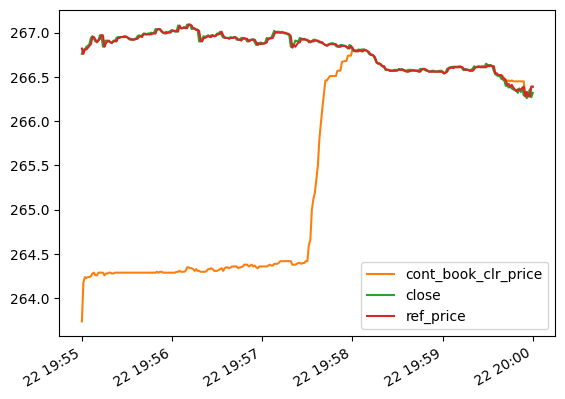

In [23]:
plt.plot(plot_df['ts_event'], plot_df['cont_book_clr_price'], label='cont_book_clr_price', color='tab:orange')
plt.plot(plot_df['ts_event'], plot_df['close'], label='close', color='tab:green')
plt.plot(plot_df['ts_event'], plot_df['ref_price'], label='ref_price', color='tab:red')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

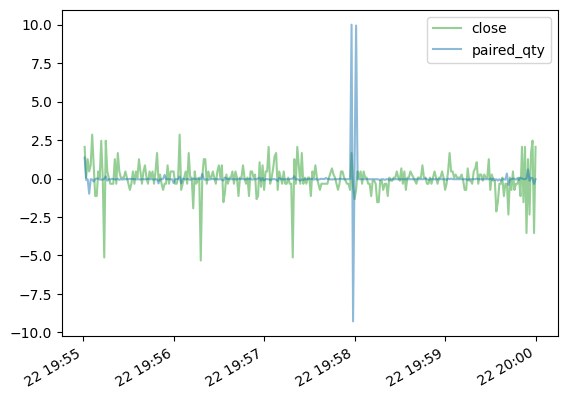

In [24]:
# plt.plot(plot_df['ts_event'], plot_df['cont_book_clr_price'].pct_change(), label='cont_book_clr_price', color='tab:orange')
plt.plot(plot_df['ts_event'], (plot_df['close'].pct_change() - plot_df['close'].pct_change().mean()) / plot_df['close'].pct_change().std(),
         label='close', color='tab:green', alpha=0.5)
# plt.plot(plot_df['ts_event'], plot_df['ref_price'].pct_change(), label='ref_price', color='tab:red')
plt.plot(plot_df['ts_event'], (plot_df['paired_qty'].pct_change() - plot_df['paired_qty'].pct_change().mean()) / plot_df['paired_qty'].pct_change().std(),
         label='paired_qty', color='tab:blue', alpha=0.5)
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

### Finding Each beta_i over rolling window
r_i ~ beta_i * r_mkt * w_i, find the beta_i

In [25]:
rets = data.group_by_dynamic(index_column='ts_event', group_by='symbol', every='1m').agg(pl.col('close').last()).with_columns(pl.col("close").pct_change().over("symbol").alias('return')).drop_nulls()

In [28]:
# Daily OLS beta to SPY using minute returns from the preceding 5 trading days
# (current day excluded). Vectorized polars: aggregate per (symbol, date) to
# sufficient stats, then rolling-sum across the prior 5 days.
#
# beta = Cov(r_i, r_spy) / Var(r_spy)
#      = (Σxy - Σx·Σy / n) / (Σy² - (Σy)² / n)        (the (n-1) cancels)

spy_rets = (
    rets.filter(pl.col("symbol") == "SPY")
        .select("ts_event", pl.col("return").alias("r_spy"))
)

daily_stats = (
    rets.join(spy_rets, on="ts_event", how="inner")
        .with_columns(pl.col("ts_event").dt.date().alias("date"))
        .group_by(["symbol", "date"])
        .agg(
            pl.len().alias("n"),
            pl.col("return").sum().alias("sx"),
            pl.col("r_spy").sum().alias("sy"),
            (pl.col("return") * pl.col("r_spy")).sum().alias("sxy"),
            (pl.col("r_spy") ** 2).sum().alias("sy2"),
        )
        .sort(["symbol", "date"])
)

w = 10
# shift(1) drops today out of the window; rolling_sum(5) sums the prior 5 days.
sum_cols = ["n", "sx", "sy", "sxy", "sy2"]
rolled = daily_stats.with_columns([
    pl.col(c).shift(1).rolling_sum(window_size=w).over("symbol").alias(f"{c}_{w}d")
    for c in sum_cols
])

betas = (
    rolled
    .with_columns(
        (
            (pl.col(f"sxy_{w}d") - pl.col(f"sx_{w}d") * pl.col(f"sy_{w}d") / pl.col(f"n_{w}d"))
            / (pl.col(f"sy2_{w}d") - pl.col(f"sy_{w}d") ** 2 / pl.col(f"n_{w}d"))
        ).alias("beta")
    )
    .filter(pl.col(f"n_{w}d") >= 30)
    .select(["date", "symbol", "beta"])
)

# Wide form: one row per date, one column per symbol.
betas_wide = betas.pivot(index="date", on="symbol", values="beta").sort("date")
betas_wide

date,A,AA,AAAU,AACG,AAL,AAMI,AAOI,AAON,AAOX,AAP,AAPB,AAPD,AAPL,AAPU,AAPX,AARD,AAT,AAUC,AAXJ,AB,ABAT,ABBV,ABCB,ABCL,ABEO,ABEV,ABG,ABM,ABNB,ABOS,ABR,ABSI,ABT,ABTC,ABTS,ABUS,…,ZAP,ZBAO,ZBH,ZBIO,ZBRA,ZCMD,ZD,ZENA,ZEO,ZEPP,ZETA,ZG,ZGN,ZH,ZIM,ZION,ZIP,ZKH,ZLAB,ZM,ZNTL,ZONE,ZOOZ,ZROZ,ZS,ZSL,ZSQR,ZTO,ZTR,ZTS,ZUMZ,ZURA,ZVIA,ZVRA,ZVZZT,ZWS,ZYME
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-05-11,1.215642,1.201732,0.417347,null,0.774826,-0.682473,1.692003,-0.7666,8.29791,0.658179,null,-0.894416,1.299259,2.469164,3.709812,2.587544,0.530979,0.870395,0.658149,0.314762,-0.056813,0.374692,0.417111,-3.468792,1.128259,0.106017,0.698201,-0.861769,0.409722,-2.439522,0.084492,-2.225005,0.116025,-0.376192,null,1.263271,…,null,null,-0.175232,0.672358,0.003869,null,0.095196,-0.618298,4.358798,-12.145709,1.608449,0.284363,1.091223,-0.011614,0.218153,0.736,2.433115,null,-0.052235,0.279852,-2.243236,null,-9.940106,0.168196,0.919542,-1.536942,-1.038171,0.263971,null,0.562604,-1.198804,-0.690665,3.666243,0.632831,null,-0.103359,0.476561
2026-05-12,1.009156,1.158088,0.432587,18.722939,1.076018,-0.591068,1.394195,-0.718534,7.793527,0.533064,3.740593,-0.845766,1.268714,2.42844,3.357135,1.517827,0.323104,1.249861,0.684802,-0.89294,-0.365689,0.458323,0.419823,-3.402594,1.176522,-0.069773,0.748687,-0.702332,0.407683,-1.916981,0.24797,-2.016738,0.074826,0.201195,null,1.461821,…,null,null,-0.108677,0.5693,0.219812,null,0.542559,-0.611978,4.434185,-10.673358,1.572473,0.463157,1.080531,0.246879,0.240624,0.682981,1.831031,0.859871,0.112345,0.450656,-1.916243,-20.420742,-10.319679,0.261154,0.859558,-1.600799,0.198043,0.293868,null,0.517729,-0.931097,-0.404903,3.431146,0.289297,null,-0.003692,0.6037
2026-05-13,0.981009,1.09724,0.193192,null,1.019119,-0.852453,1.876795,-0.129546,7.412327,0.585712,3.342578,-0.954608,1.282817,2.567114,-0.528358,1.434918,0.172569,1.200543,0.687015,-0.713361,-0.789471,0.313182,0.441427,-3.136402,0.949117,0.31026,0.799961,-0.556086,0.276563,-2.031472,0.071814,-1.935552,-0.015098,2.858691,-38.88434,1.056275,…,null,null,-0.238626,0.610436,0.071947,30.115699,0.646571,-0.524551,null,14.860709,1.632864,0.340532,0.995041,0.410254,0.184197,0.688898,2.227667,0.62294,0.079667,0.593426,-1.975692,-22.842979,-10.038302,0.304837,0.750098,-1.616379,1.54611,0.290259,null,0.425371,-1.080398,-0.55755,2.139455,0.269344,null,-0.069882,0.631583
2026-05-14,0.624036,1.109338,0.068054,null,0.853686,0.02208,2.604761,-0.141028,8.562662,0.450504,3.639857,-1.009217,1.233344,2.570795,-5.102467,2.009982,0.141899,1.06231,-0.556846,-1.992162,-0.914195,0.368957,0.88301,-3.635275,0.800425,0.38932,1.077767,-0.585312,-0.071801,-0.127475,0.486942,0.094745,0.221332,3.734376,-39.087851,0.062975,…,null,null,0.263124,-0.478328,0.135795,null,0.869135,-1.603326,null,9.151399,1.560281,0.420156,1.686031,2.82337,-0.354363,0.84054,1.292993,0.427972,-0.090941,0.711718,-0.735148,-14.401522,-19.901787,0.748911,0.925142,-1.445551,2.800326,-0.046782,null,0.488402,-2.517942,0.081276,4.098843,0.240678,null,0.395958,0.582806
2026-05-15,0.496751,0.800343,0.056102,null,0.781173,0.46608,3.849213,0.167104,10.782254,0.294473,2.430382,-0.545096,1.010557,2.192205,null,0.914942,0.023453,0.924728,-1.022757,-1.586031,-0.483762,0.260483,0.84505,-0.853242,1.277864,0.408379,1.184065,0.88574,-0.174411,1.040637,0.014268,-1.580902,0.183159,2.777843,null,-0.955472,…,null,null,0.29953,-0.619343,0.450445,29.337521,0.675842,-2.755838,12.63229,11.154543,1.696649,0.290832,1.319432,3.380574,0.014178,0.720287,1.357137,-0.726405,-0.221756,0.843185,0.163906,-19.967267,-8.125553,0.606157,1.06118,-1.441337,4.481011,0.086585,null,0.230001,-2.494423,-0.021278,3.119009,-0.461692,null,1.010342,0.875915
2026-05-18,0.5413,1.061507,-0.022001,null,1.034856,0.726389,2.694354,-